# Fuzzy Sets application: IT Incident Priorization using Control systems


## Imports

In [1]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl

## Antecedents:

### 1) Breadth & Criticality: Resp. who and what is affected, & to what extent ?

- I personally would separate the service's "impact" into two antecedents:
  - Breadth: How many users and workers are affected ( I think both many affected employees and many affected clients/users seem like comparably bad scenarios !)
      - We can consider the breadth score to range from 0 to 1, or 0 to 100, from no user of those services to absolutely everyone it could affect. Fuzzy variables could be something like: low, moderate, high, and most users/ "critical" (amount of affected clients or personel).
  - Criticality: How impactful is the service from which the incident is reported to have occured ? It may not impact many users but the reduced functionality of the service may affect the whole line of command.
      - We can consider the service criticality to range from 0 to 100, the score can describe how "important" this service is for other services' functioning. 0 can be "no other service aside from this one will be impacted", to 100, "everything else is affected". The actual fuzzy variable I can propose are: low, moderate, high and critical.

C:\Users\Sara\Documents\fuzzy\fuzzy-tutorial\venv\lib\site-packages\skfuzzy\control\fuzzyvariable.py:122: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


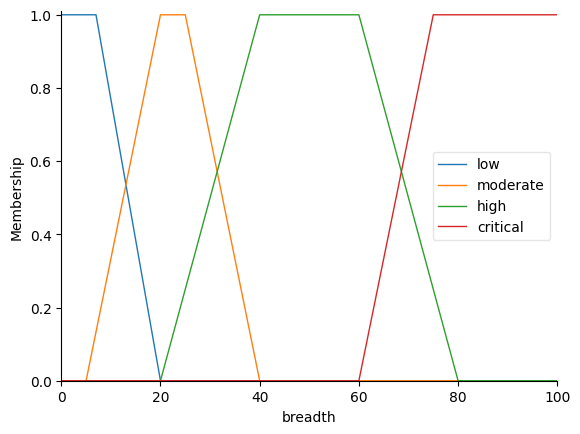

In [2]:
breadth = ctrl.Antecedent(np.arange(0, 101, 1), 'breadth')

breadth['low'] = fuzz.trapmf(breadth.universe, [0, 0, 7, 20])
breadth['moderate'] = fuzz.trapmf(breadth.universe, [5, 20, 25, 40])
breadth['high'] = fuzz.trapmf(breadth.universe, [20, 40, 60, 80])
breadth['critical'] = fuzz.trapmf(breadth.universe, [60, 75, 100, 100])

breadth.view()

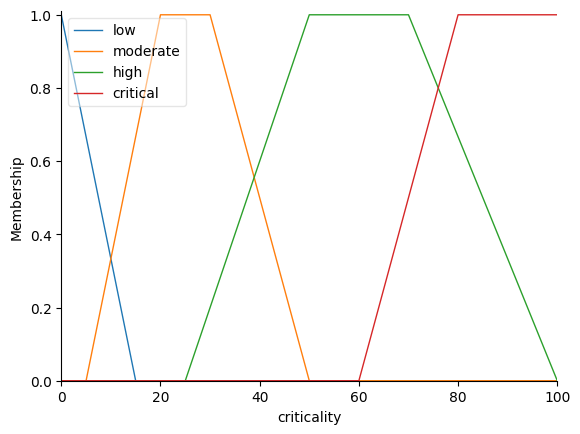

In [3]:
criticality = ctrl.Antecedent(np.arange(0, 101, 1), 'criticality')

criticality['low'] = fuzz.trimf(criticality.universe, [0,  0, 15])
criticality['moderate'] = fuzz.trapmf(criticality.universe, [5, 20, 30, 50])
criticality['high'] = fuzz.trapmf(criticality.universe, [25, 50, 70, 100])
criticality['critical'] = fuzz.trapmf(criticality.universe, [60, 80, 100, 100])

criticality.view()

### 2) Severity: How bad is the loss in functionality ?

- Severity could range from completely harmless consequences, to minor issues not affecting people's work, to performance issues, to low, partial or complete service outage !
- Severity score could range from 0 to 100, and we could categorize an incident as minor (minor impact on functionality, including performance issues IMO), partial, or complete service outage.

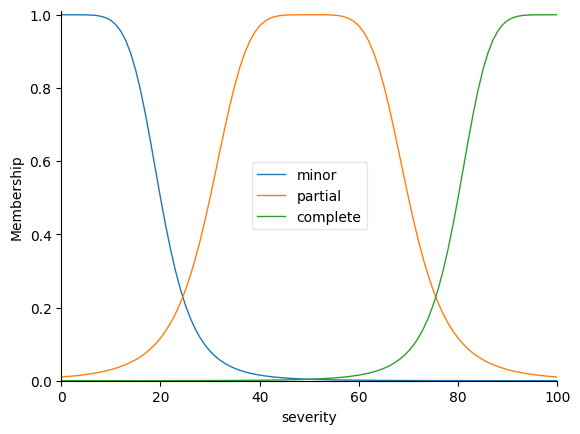

In [4]:
# i'm just trying out gaussian bells here, but it really seems interchangeable with single triangles in this example.
severity = ctrl.Antecedent(np.arange(0, 101, 1), 'severity')

severity['minor'] = fuzz.gbellmf(severity.universe, 20, 3, 0)
severity['partial'] = fuzz.gbellmf(severity.universe, 20, 2.5, 50)
severity['complete'] = fuzz.gbellmf(severity.universe, 20, 3, 100)

severity.view()

### 3) Urgency: How likely is it that this incidents degrades over time, and to what extent ?

- Is it reported that the incident is actively degrading, are there existing workarounds until the incident is fixed, or is the service not urgently needed ? I believe this one is a bit tricky because it has many different factors to consider on its own.
- But for now let's just say that the urgency score is determined based on how urgently needed the IT support team's attention is.
- Urgency score will range from 0 to 1 or 0 to 100, and fuzzy variables range from "very low" (we can really do without for a while), to low, moderate, high, critical (we need a fix NOW and don't have any workaround !)

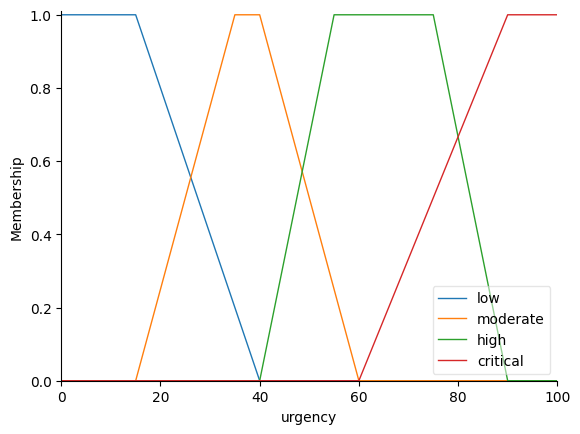

In [5]:
urgency = ctrl.Antecedent(np.arange(0, 101, 1), 'urgency')


urgency['low'] = fuzz.trapmf(urgency.universe, [0, 0, 15, 40])
urgency['moderate'] = fuzz.trapmf(urgency.universe, [15, 35, 40, 60])
urgency['high'] = fuzz.trapmf(urgency.universe, [40, 55, 75, 90])
urgency['critical'] = fuzz.trapmf(urgency.universe, [60, 90, 100, 100])

urgency.view()

## Consequent:

### IT Incident Priority

- For our consequent, we can consider a priority score ranging from 0 to 100,
- With the following fuzzy variables: Low priority, medium, high and critical priority.

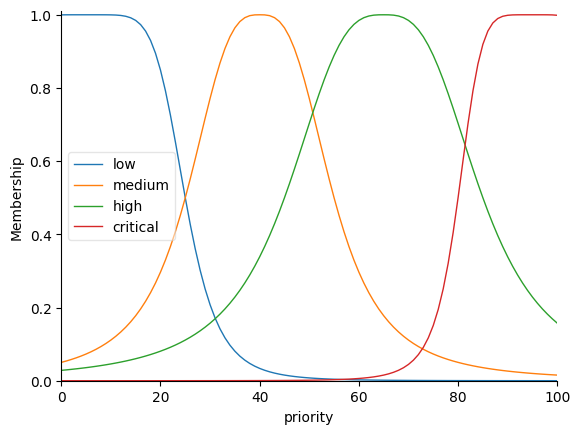

In [6]:
priority = ctrl.Consequent(np.arange(0, 101, 1), 'priority', defuzzify_method = 'centroid')

priority['low'] = fuzz.gbellmf(priority.universe, 20, 3, 5)
priority['medium'] = fuzz.gbellmf(priority.universe, 15, 1.5, 40)
priority['high'] = fuzz.gbellmf(priority.universe, 20, 1.5, 65)
priority['critical'] = fuzz.gbellmf(priority.universe, 15, 3, 95)

priority.view()

## Fuzzy Rules

My initial thinking is as such: We could center our rules around how **urgent** or **severe** an incident is:
- If an service completely halts or if it is considered very urgent to solve, and there is many affected users or services, the priority is likely to be critical
- Conversely, if it is not at all urgent or severe, but it affects many people, we may say the incident is not low in priority but not the highest either.
- So I based these rules on such kinds of reasoning. Will probably have to refine this later.


In [7]:
r1 = ctrl.Rule(urgency["critical"] & severity["complete"], priority['critical'])
r2 = ctrl.Rule(urgency["critical"] & severity["partial"], priority['critical'])
r3 = ctrl.Rule(urgency["high"] & severity["complete"], priority['critical'])

r4 = ctrl.Rule(urgency["critical"] & severity["minor"], priority['high'])
r5 = ctrl.Rule(urgency["high"] & severity["partial"], priority['high'])
r6 = ctrl.Rule(urgency["moderate"] & severity["complete"], priority['high'])

r7 = ctrl.Rule((severity["complete"] | urgency["high"]) & (breadth["critical"] | criticality["critical"]), priority['critical'])
r8 = ctrl.Rule((severity["complete"] & urgency["moderate"]) & (breadth["high"] | criticality["high"]), priority['critical'])
r13 = ctrl.Rule((severity["partial"] & urgency["high"]) & (breadth["high"] | criticality["high"]), priority['critical'])
r9 = ctrl.Rule((severity["partial"] | urgency["moderate"]) & (breadth["critical"] | criticality["critical"]), priority['high'])
r10 = ctrl.Rule((severity["complete"] | urgency["critical"]) & (breadth["moderate"] | criticality["moderate"]), priority['high'])
r11 = ctrl.Rule((severity["complete"] | urgency["critical"]) & (breadth["low"] | criticality["low"]), priority['medium'])

r12 = ctrl.Rule(breadth["low"] & criticality["low"], priority['low'])


## Control System Creation and Simulation

In [8]:
priority_ctrl = ctrl.ControlSystem([r1, r2, r3, r4, r5, r6, r7, r8, r9, r10, r11, r12, r13])
priority_ctrl.defuzzify_method = 'bisector'
priority_sim = ctrl.ControlSystemSimulation(priority_ctrl)


### Testing out potential scenarios


Priority outcome value: 61.88


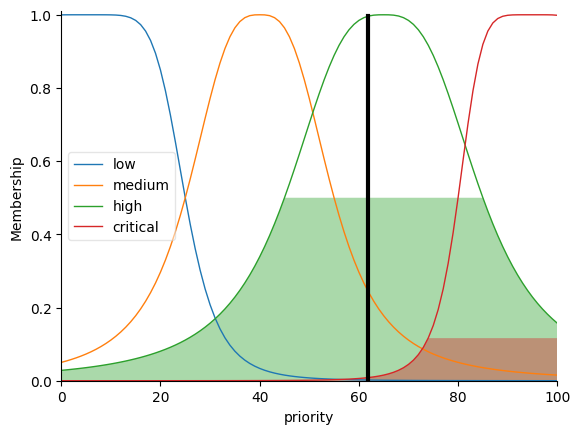

In [9]:
priority_sim.input['breadth'] = 20
priority_sim.input['criticality'] = 30
priority_sim.input['severity'] = 20
priority_sim.input['urgency'] = 75

priority_sim.compute()

print("Priority outcome value: %.2f" %  priority_sim.output['priority'])
priority.view(sim=priority_sim)


Priority outcome value: 67.99


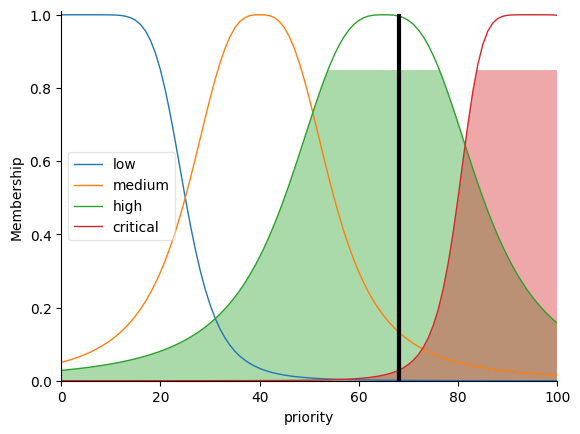

In [10]:
priority_sim.input['breadth'] = 20
priority_sim.input['criticality'] = 30
priority_sim.input['severity'] = 85
priority_sim.input['urgency'] = 75

priority_sim.compute()

print("Priority outcome value: %.2f" %  priority_sim.output['priority'])
priority.view(sim=priority_sim)


In [11]:
different_cases = {
    "low everything":{
        'breadth':5,
        'criticality':5,
        'severity':10,
        'urgency':10,
    },
    "high severity, low other things":{
        'breadth':5,
        'criticality':5,
        'severity':95,
        'urgency':10,
    },
    "relatively high everything":{
        'breadth':95,
        'criticality':75,
        'severity':90,
        'urgency':85,
    },
    "low severity, high other things":{
        'breadth':95,
        'criticality':85,
        'severity':10,
        'urgency':85,
    }
}

methods = ['centroid', 'bisector', 'mom', 'som', 'lom']

for name, case in different_cases.items():
    print(f"new test case: {name}\n")
    
    for method in methods:
        priority_ctrl.defuzzify_method = method
        priority_sim = ctrl.ControlSystemSimulation(priority_ctrl)
    
        for variable, value in case.items():
            priority_sim.input[variable] = value
    
        priority_sim.compute()
        print(f"{method}: {priority_sim.output['priority']:.2f}")
    print(f"\n---")

new test case: low everything

centroid: 15.13
bisector: 15.13
mom: 15.13
som: 15.13
lom: 15.13

---
new test case: high severity, low other things

centroid: 33.07
bisector: 33.07
mom: 33.07
som: 33.07
lom: 33.07

---
new test case: relatively high everything

centroid: 84.14
bisector: 84.14
mom: 84.14
som: 84.14
lom: 84.14

---
new test case: low severity, high other things

centroid: 63.45
bisector: 63.45
mom: 63.45
som: 63.45
lom: 63.45

---


## Conclusions:

It seems very sus that all defuzzification methods return the same value each as each other, but i lack the time to investigate for now !

It was an interesting test and definitely pumped that we will compare and debate with the rest of the group later on.